<a href="https://colab.research.google.com/github/RolandoRobledo/Equipo-programacion-para-inteligencia-artificial/blob/main/ACTIVIDAD_FUNDAMENTAL_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **ACTIVIDAD FUNDAMENTAL 3**

Equipo
*   Rolando Robledo Garcia 2182694
*   Angel Dario Reyes Garza 2194347
*   Ethan Raul Leos Rodriguez 2190405
*   Ruben Alejandro Garcia Zalpa 2188593
*   Gonzalo Isaias Mora Garcia 2276161


Carga del Conjunto de Datos Público

Primero Importamos las librerías Pandas y NumPy para la manipulación e inspección de datos, Matplotlib para la visualización, y los módulos de scikit-learn para la división del dataset, la construcción del árbol de decisión, su graficación y la evaluación del modelo.

In [119]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report

In [120]:
# Carga del Dataset
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
columnas = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

df = pd.read_csv(url, header=None, names=columnas)
print("--- Primeras filas del dataset original ---")
print(df.head())
print("\n" + "="*50 + "\n")

--- Primeras filas del dataset original ---
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  




 Análisis Exploratorio y Visualización

 Hacemos el análisis exploratorio sacando el resumen estadístico con df.describe y la información general del dataset con df.info. Después armamos un gráfica de dispersión con Matplotlib para comparar la glucosa contra el índice de masa corporal, separando por colores a los pacientes con y sin diabetes.


In [121]:
# Análisis Exploratorio y Visualización
print("Resumen estadístico completo")
print(df.describe())

print("\nInformación general y valores nulos")
print(df.info())


Resumen estadístico completo
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min   

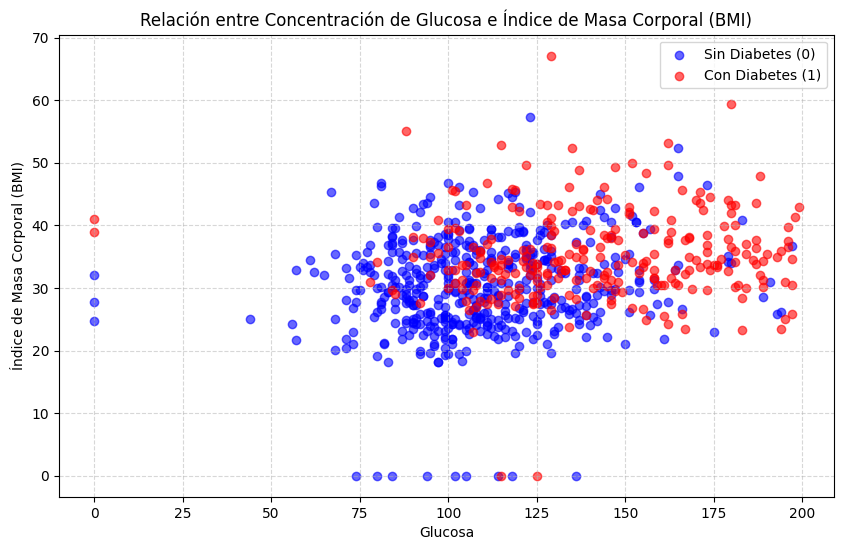

In [122]:
# Visualización: Diagrama de Dispersión (Glucose vs BMI por Outcome)
plt.figure(figsize=(10, 6))

sin_diabetes = df[df['Outcome'] == 0]
con_diabetes = df[df['Outcome'] == 1]

plt.scatter(sin_diabetes['Glucose'], sin_diabetes['BMI'], color='blue', alpha=0.6, label='Sin Diabetes (0)')
plt.scatter(con_diabetes['Glucose'], con_diabetes['BMI'], color='red', alpha=0.6, label='Con Diabetes (1)')

plt.title('Relación entre Concentración de Glucosa e Índice de Masa Corporal (BMI)')
plt.xlabel('Glucosa')
plt.ylabel('Índice de Masa Corporal (BMI)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

 Limpieza y Preprocesamiento de Datos

 Primero cambiamos los ceros por valores nulos NaN en las columnas donde no hace sentido biológico tener cero. Luego imputamos esos nulos rellenándolos con la mediana calculada por cada grupo de Outcome(Se utilizo la mediana debido a que era el que daba un mejor resultado que si se usaba el promedio). Por último, usamos NumPy para sacar los percentiles 25 y 75 de Insulin, sacamos el rango intercuartílico e imputamos o filtramos los outliers dejando solo los registros dentro de los límites válidos.

In [123]:
# Limpieza y Preprocesamiento de Datos

# Detección de nulos encubiertos
cols_biologicas = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols_biologicas] = df[cols_biologicas].replace(0, np.nan)

# Imputación condicional: mediana por grupo de 'Outcome' (Con / Sin Diabetes)
for col in cols_biologicas:
    df[col] = df.groupby('Outcome')[col].transform(lambda group: group.fillna(group.median()))

# Tratamiento de valores atípicos (Outliers) en 'Insulin' por IQR
q25, q75 = np.percentile(df['Insulin'], [25, 75])
iqr = q75 - q25
limite_inferior = q25 - (1.5 * iqr)
limite_superior = q75 + (1.5 * iqr)

df_limpio = df[(df['Insulin'] >= limite_inferior) & (df['Insulin'] <= limite_superior)].copy()

print("\nTamaño del dataset")
print(f"Original: {df.shape[0]} muestras | Tras eliminar outliers de Insulin: {df_limpio.shape[0]} muestras\n")


Tamaño del dataset
Original: 768 muestras | Tras eliminar outliers de Insulin: 717 muestras



In [124]:
# Entrenamiento y Evaluación del Árbol de Decisión

X = df_limpio.drop(columns=['Outcome'])
y = df_limpio['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

modelo = DecisionTreeClassifier(max_depth=3, random_state=42)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
exactitud = accuracy_score(y_test, y_pred)

print(f"Exactitud: {exactitud:.4f}\n")
print("Reporte de Clasificación")
print(classification_report(y_test, y_pred, target_names=['Sin Diabetes', 'Con Diabetes']))

Exactitud: 0.8944

Reporte de Clasificación
              precision    recall  f1-score   support

Sin Diabetes       0.93      0.91      0.92       120
Con Diabetes       0.83      0.87      0.85        60

    accuracy                           0.89       180
   macro avg       0.88      0.89      0.88       180
weighted avg       0.90      0.89      0.90       180



In [125]:
modelo.score(X_train, y_train)

0.9050279329608939

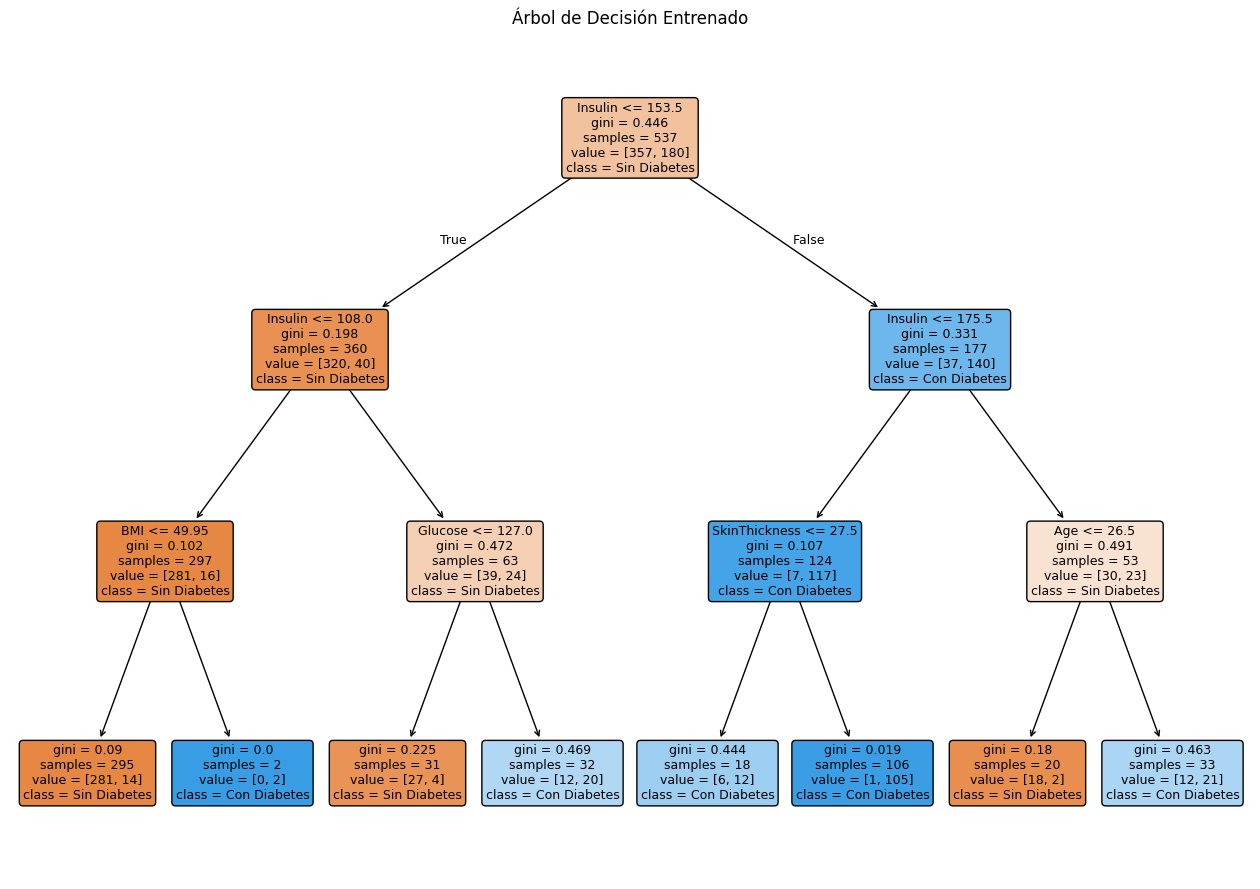

In [126]:
# Visualización de la Estructura del Árbol
plt.figure(figsize=(16, 11))
plot_tree(
    modelo,
    feature_names=X.columns,
    class_names=['Sin Diabetes', 'Con Diabetes'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Árbol de Decisión Entrenado")
plt.show()